In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import fsolve

In [2]:
# Set theme
sns.set_theme(style="ticks")
figsize = (8, 6)

# Define grid space
x = np.linspace(-16, 16, 641)
y = np.linspace(-12, 12, 481)
X, Y = np.meshgrid(x, y)

# Define Constants
G = 1 # Gravitational constant in arbitrary units
m1 = 10 # Mass of the first body in kg
m2 = 1 # Mass of the second body in kg

# Define positions of the two bodies
R = 10 # Distance between the two bodies in the original frame
_r1 = np.array([-R/2, 0]) # Position of the first body in the original frame
_r2 = np.array([R/2, 0]) # Position of the second body in the original frame
r_com = (m1*_r1 + m2*_r2) / (m1 + m2)
r1 = _r1 - r_com # Position of the first body relative to the center of mass
r2 = _r2 - r_com # Position of the second body relative to the center of mass

Ω = np.array([0, 0, np.sqrt(G * (m1 + m2) / R**3)]) # Angular velocity of the rotating frame

v = np.zeros(3) # Velocity of the test particle in the rotating frame

In [3]:
# Define potentials U and U_eff, note small mass set to unity
U = -G*(m1/np.sqrt((X-r1[0])**2 + (Y-r1[1])**2) + m2/np.sqrt((X-r2[0])**2 + (Y-r2[1])**2))

grid_r = np.stack((X, Y, np.zeros_like(X)), axis=0)

Ω_cross_r = np.cross(
    Ω[:, None, None],
    grid_r,
    axisa=0,
    axisb=0,
    axisc=0
)

U_eff = (U - np.einsum('i,ijk->jk', v, Ω_cross_r) - 0.5 * np.sum(Ω_cross_r**2, axis=0))

In [4]:
# Numeric calculation of the Lagrange points

# Define α and β parameters
α = m2 / (m1 + m2)
β = m1 / (m1 + m2)

# Define force function
def force(coord: tuple, mass_ratios = (α, β)) -> tuple:
    """Gives the force of the force at a point (x, y)

    Args:
        x float: x-coordinate of the point
        y float: y-coordinate of the point
    Returns:
        tuple: Force components (fx, fy) at the point (x, y)
    """
    x, y = coord
    α, β = mass_ratios
    Ω2 = np.dot(Ω, Ω)
    # Define the force components
    fx = Ω2 * (x - (β*(x + α*R)*R**3)/((x + α*R)**2 + y**2)**(3/2) - (α*(x - β*R)*R**3)/((x - β*R)**2 + y**2)**(3/2))
    fy = Ω2 * (y - (β*y*R**3)/((x + α*R)**2 + y**2)**(3/2) - (α*y*R**3)/((x - β*R)**2 + y**2)**(3/2))
    return fx, fy

# Define function to find Lagrange points
def find_lagrange_point(guess: tuple, mass_ratios = (α, β)) -> tuple:
    """Finds the Lagrange point given an initial guess

    Args:
        guess (tuple): Initial guess for the Lagrange point (x, y)
    Returns:
        tuple: Coordinates of the Lagrange point (x, y)
    """
    def f(coord, mass_ratios = (α, β)):
        return force(coord, mass_ratios)
    gx = guess[0]
    gy = guess[1]
    lx = fsolve(f, (gx, gy))[0]
    ly = fsolve(f, (gx, gy))[1]
    return (lx, ly)

# Find Lagrange points numerically
lagrange_points = [
    find_lagrange_point((R/2, 0)),  # L1
    find_lagrange_point((R, 0)),  # L2
    find_lagrange_point((-R, 0)), # L3
    find_lagrange_point((R/2, np.sqrt(3)*R/2)),  # L4
    find_lagrange_point((R/2, -np.sqrt(3)*R/2))  # L5
]

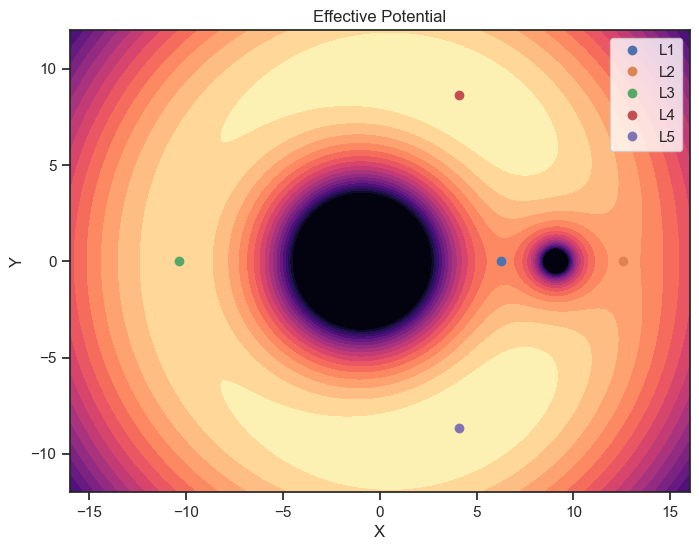

In [5]:
# Create plot
fig, ax = plt.subplots(figsize=figsize)

# Potential heatmap
heatmap = ax.contourf(X, Y, np.maximum(U_eff, -3), 20, cmap='magma')

# Plot Lagrange points, either approx or exact
for i, point in enumerate(lagrange_points, start=1):
    ax.plot(point[0], point[1], 'o', label=f'L{i}')
ax.legend()

# Add colorbar
# cbar = plt.colorbar(heatmap, ax=ax)
# cbar.set_label('Effective Potential')

# Plot labels
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_title('Effective Potential')
plt.savefig('plots/ueff.png')
plt.show()

We can see that the Lagrange points align approximately with the minima and maxima of the potential, but to get a better idea, we can take the gradient of this potential to get a plot of the force.

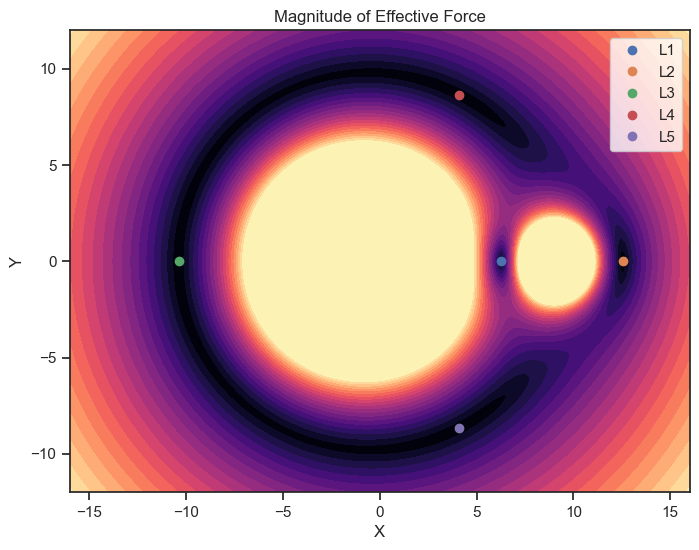

In [6]:
# Create plot
fig, ax = plt.subplots(figsize=figsize)

# Force heatmap
F = np.sqrt((-np.gradient(U_eff)[1])**2 + (-np.gradient(U_eff)[0])**2)
heatmap = ax.contourf(X, Y, np.minimum(F, 1e-2), 20, cmap='magma')

# Plot Lagrange points, either approx or exact
for i, point in enumerate(lagrange_points, start=1):
    ax.plot(point[0], point[1], 'o', label=f'L{i}')
ax.legend()

# Plot labels
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_title('Magnitude of Effective Force')
plt.savefig('plots/feff.png')
plt.show()

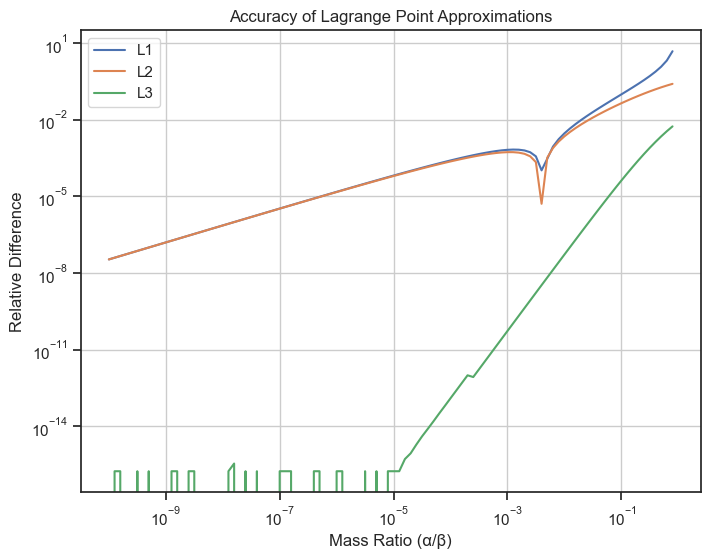

In [7]:
# Consider acuuracy of the approximation of the Lagrange points by comparing the approximate and exact values

# Compare the approximate and exact values of the Lagrange points for different mass ratios
mass_ratios = np.power(10., np.arange(-10, 0, .1))
l_diffs = np.zeros((len(mass_ratios), 5))

for i, r in enumerate(mass_ratios):
    m1 = 1/r
    m2 = 1
    α = m2 / (m1 + m2)
    β = m1 / (m1 + m2)
    approx_points = np.array([
        (R*(1-(α/3)**(1/3)), 0),
        (R*(1+(α/3)**(1/3)), 0),
        (-R*(1+(5/12)*α), 0),
        ((R/2)*((m1-m2)/(m1+m2)), (R/2)*np.sqrt(3)),
        ((R/2)*((m1-m2)/(m1+m2)), -(R/2)*np.sqrt(3))
    ])
    exact_points = np.array([
        find_lagrange_point((R/2, 0), (α, β)),  # L1
        find_lagrange_point((R, 0), (α, β)),  # L2
        find_lagrange_point((-R, 0), (α, β)), # L3
        find_lagrange_point((R/2, np.sqrt(3)*R/2), (α, β)),  # L4
        find_lagrange_point((R/2, -np.sqrt(3)*R/2), (α, β))  # L5
    ])
    l_diffs[i] = np.linalg.norm(exact_points - approx_points, axis=1)/np.linalg.norm(exact_points, axis=1)
    
# Plot the differences
plt.figure(figsize=(8, 6))
for i in range(3):
    plt.loglog(mass_ratios, l_diffs[:, i], label=f'L{i+1}')
    plt.xlabel('Mass Ratio (α/β)')
    plt.ylabel('Relative Difference')
    plt.title('Accuracy of Lagrange Point Approximations')
    plt.legend()
    plt.grid(True)
    plt.savefig('plots/mass_ratio_accuracy.png')